# 01 · Getting a feel for CLIP

A hands-on first look at CLIP, before building the real pipeline.

1. Load the model and see what it produces
2. Compare texts with each other in the embedding space
3. Zero-shot classification (CIFAR-10)
4. Text-to-image retrieval on faces (FairFace)
5. A first, rough look at bias in the retrieved images



In [1]:
!pip -q install open_clip_torch datasets

In [2]:
import torch, open_clip, numpy as np, matplotlib.pyplot as plt
from collections import Counter

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0); np.random.seed(0)
print("device:", device)

device: cuda


## 1. Load CLIP

`open_clip` returns three things:
- **model**: the image encoder + the text encoder
- **preprocess**: resizes / crops / normalises an image the way CLIP was trained
- **tokenizer**: turns text into token ids (max 77 tokens)

In [3]:
model, _, preprocess = open_clip.create_model_and_transforms("ViT-B-32", pretrained="openai")
tokenizer = open_clip.get_tokenizer("ViT-B-32")
model = model.to(device).eval()

n_img = sum(p.numel() for p in model.visual.parameters())
n_all = sum(p.numel() for p in model.parameters())
print(f"image encoder: {n_img/1e6:.0f}M params | text encoder + rest: {(n_all-n_img)/1e6:.0f}M params")
print(preprocess)

open_clip_model.safetensors: reconstructing file:   0%|          |  0.00B /  605MB            

open_clip_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


image encoder: 88M params | text encoder + rest: 63M params
Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeConvertMode()
    MaybeToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)


## 2. Text embeddings

Every text becomes **one vector of 512 numbers**. We normalise it to length 1, so the dot product between two vectors is their **cosine similarity** (1 = same direction, 0 = unrelated).

shape: (6, 512)


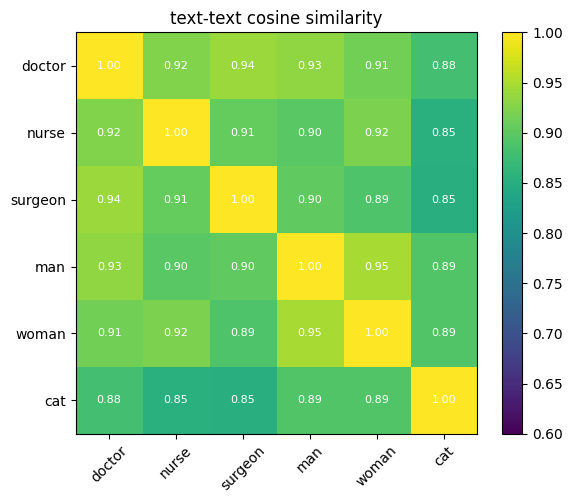

In [4]:
@torch.no_grad()
def encode_text(texts):
    tokens = tokenizer(texts).to(device)
    emb = model.encode_text(tokens)
    return emb / emb.norm(dim=-1, keepdim=True)

texts = ["a photo of a doctor", "a photo of a nurse", "a photo of a surgeon",
         "a photo of a man", "a photo of a woman", "a photo of a cat"]
T = encode_text(texts)
print("shape:", tuple(T.shape))

sim = (T @ T.T).cpu().numpy()
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(sim, vmin=0.6, vmax=1, cmap="viridis")
ax.set_xticks(range(len(texts)), [t.replace("a photo of a ", "") for t in texts], rotation=45)
ax.set_yticks(range(len(texts)), [t.replace("a photo of a ", "") for t in texts])
for i in range(len(texts)):
    for j in range(len(texts)):
        ax.text(j, i, f"{sim[i,j]:.2f}", ha="center", va="center", fontsize=8, color="w")
plt.colorbar(im); plt.title("text-text cosine similarity"); plt.tight_layout(); plt.show()

**Look at:** I see there is even bias here. "doctor" and "surgeon" is more correlated to "man" than "woman", "nurse" is more correlated to "woman" than "men".

## 3. Zero-shot classification

No training: we write one sentence per class, embed the image, and pick the class whose sentence is most similar. The ×100 is CLIP's learned temperature (≈ 1/τ).

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  120MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 23.9MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

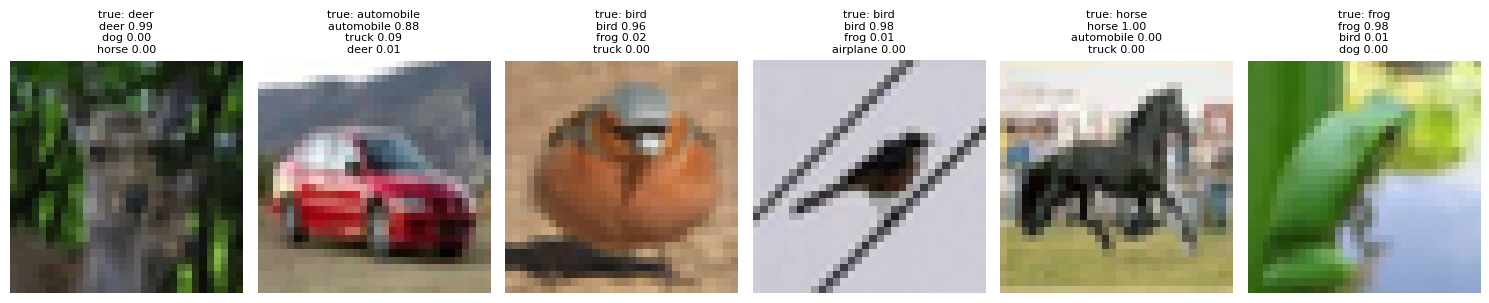

In [9]:
from datasets import load_dataset

cifar_hf = load_dataset("uoft-cs/cifar10", split="test")
classes = cifar_hf.features["label"].names
class_emb = encode_text([f"a photo of a {c}" for c in classes])

# keep the same interface as before: cifar[i] -> (image, label)
cifar = [(row["img"], row["label"]) for row in cifar_hf.select(range(2000))]
from torch.utils.data import DataLoader, Dataset

class _PILDataset(Dataset):
    def __init__(self, images): self.images = images
    def __len__(self): return len(self.images)
    def __getitem__(self, i): return preprocess(self.images[i].convert("RGB"))

@torch.no_grad()
def encode_images(pil_images, batch_size=256):
    loader = DataLoader(_PILDataset(pil_images), batch_size=batch_size,
                        num_workers=2, pin_memory=(device == "cuda"))
    out = []
    for batch in loader:
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            e = model.encode_image(batch.to(device, non_blocking=True))
        e = e.float()
        out.append(e / e.norm(dim=-1, keepdim=True))
    return torch.cat(out)

# a few examples
idx = np.random.choice(len(cifar), 6, replace=False)
imgs = [cifar[i][0] for i in idx]
probs = (100 * encode_images(imgs) @ class_emb.T).softmax(dim=-1).cpu()
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for ax, im, p, i in zip(axes, imgs, probs, idx):
    top = p.topk(3)
    ax.imshow(im); ax.axis("off")
    ax.set_title(f"true: {classes[cifar[i][1]]}\n" + "\n".join(f"{classes[k]} {v:.2f}" for v, k in zip(top.values, top.indices)), fontsize=8)
plt.tight_layout(); plt.show()

In [10]:
# accuracy on 2000 test images
n = 2000
imgs = [cifar[i][0] for i in range(n)]
labels = torch.tensor([cifar[i][1] for i in range(n)])
pred = (encode_images(imgs) @ class_emb.T).argmax(dim=-1).cpu()
print(f"zero-shot CIFAR-10 accuracy: {(pred == labels).float().mean():.1%}")

zero-shot CIFAR-10 accuracy: 86.4%


## 4. Text-to-image retrieval on FairFace

Now the task: a **gallery** of images, one **query**, rank all images by similarity, look at the top-k.

FairFace has face images labelled with gender, race and age. I use a subset of the validation split to keep it fast.

In [11]:
from datasets import load_dataset
try:
    ff = load_dataset("HuggingFaceM4/FairFace", "0.25", split="validation")
except Exception as e:
    raise RuntimeError("Could not load FairFace from the Hugging Face Hub. "
                       "Check the dataset page or download it manually from the FairFace GitHub.") from e

N = 3000  # gallery size; the full validation split is ~11k
ff = ff.shuffle(seed=0).select(range(N))
print(ff)
names = {k: ff.features[k].names for k in ["gender", "race", "age"]}
names

README.md:   0%|          | 0.00/5.89k [00:00<?, ?B/s]

0.25/train-00000-of-00002-d405faba4f4b9b(…): reconstructing file:   0%|          |  0.00B /  250MB            

0.25/train-00000-of-00002-d405faba4f4b9b(…): downloading bytes:           |  0.00B            

0.25/train-00001-of-00002-dd3cb681647274(…): reconstructing file:   0%|          |  0.00B /  250MB            

0.25/train-00001-of-00002-dd3cb681647274(…): downloading bytes:           |  0.00B            

0.25/validation-00000-of-00001-951dbd63c(…): reconstructing file:   0%|          |  0.00B / 63.2MB            

0.25/validation-00000-of-00001-951dbd63c(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/86744 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10954 [00:00<?, ? examples/s]

Dataset({
    features: ['image', 'age', 'gender', 'race', 'service_test'],
    num_rows: 3000
})


{'gender': ['Male', 'Female'],
 'race': ['East Asian',
  'Indian',
  'Black',
  'White',
  'Middle Eastern',
  'Latino_Hispanic',
  'Southeast Asian'],
 'age': ['0-2',
  '3-9',
  '10-19',
  '20-29',
  '30-39',
  '40-49',
  '50-59',
  '60-69',
  'more than 70']}

In [12]:
gallery = encode_images(ff["image"])   # (N, 512), takes ~1 min on a T4
labels = {k: np.array(ff[k]) for k in ["gender", "race", "age"]}
gallery.shape

torch.Size([3000, 512])

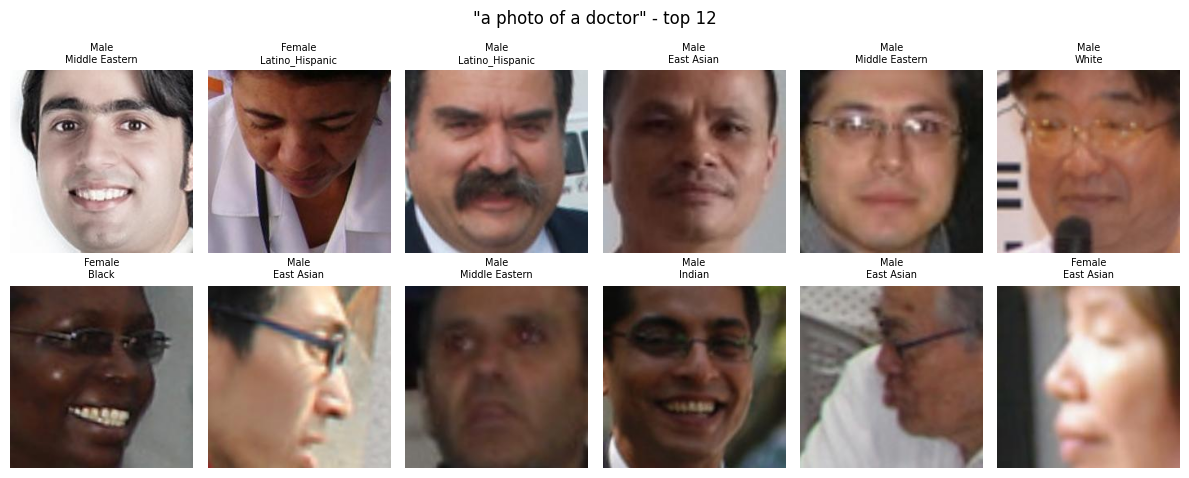

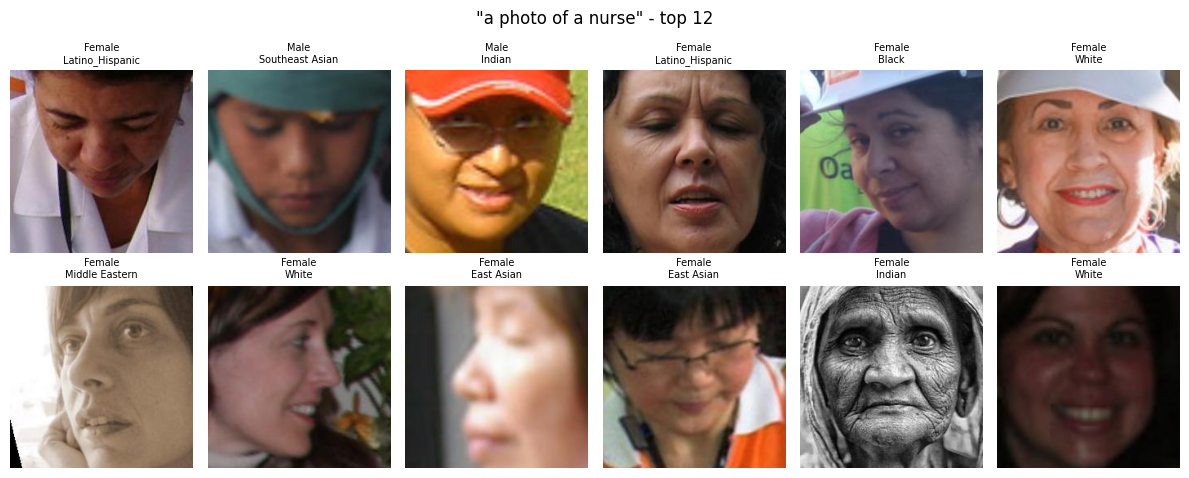

In [13]:
def search(query, k=12):
    q = encode_text([query])
    scores = (gallery @ q.T).squeeze(1)
    return scores.topk(k).indices.cpu().numpy()

def show(query, k=12):
    top = search(query, k)
    fig, axes = plt.subplots(2, k // 2, figsize=(2 * k // 2, 5))
    for ax, i in zip(axes.flat, top):
        ax.imshow(ff[int(i)]["image"]); ax.axis("off")
        ax.set_title(f"{names['gender'][labels['gender'][i]]}\n{names['race'][labels['race'][i]]}", fontsize=7)
    fig.suptitle(f'"{query}" - top {k}'); plt.tight_layout(); plt.show()

show("a photo of a doctor")
show("a photo of a nurse")

## 5. A first look at bias

For each query: what fraction of the top-100 is each group, compared with the gallery itself?

This is a rough preview of **Skew@k** (Phase 1): `skew = ln(share in top-k / share in gallery)`. Positive = over-represented, negative = under-represented. Here the reference is the **gallery composition**; the proper module will also support uniform and custom references.

In [14]:
def composition(attr, idx=None):
    vals = labels[attr] if idx is None else labels[attr][idx]
    c = Counter(vals); n = len(vals)
    return np.array([c.get(j, 0) / n for j in range(len(names[attr]))])

def skew_table(query, attr, k=100, eps=1e-6):
    top = search(query, k)
    p_top, p_ref = composition(attr, top), composition(attr)
    skew = np.log((p_top + eps) / (p_ref + eps))
    print(f'\n"{query}"  attribute={attr}  k={k}')
    for name, a, b, s in zip(names[attr], p_top, p_ref, skew):
        print(f"  {name:18s} top-k {a:5.1%}  gallery {b:5.1%}  skew {s:+.2f}")
    print(f"  MaxSkew {skew.max():+.2f}   MinSkew {skew.min():+.2f}")

for q in ["a photo of a doctor", "a photo of a nurse", "a photo of a CEO", "a photo of a criminal"]:
    skew_table(q, "gender")


"a photo of a doctor"  attribute=gender  k=100
  Male               top-k 81.0%  gallery 53.2%  skew +0.42
  Female             top-k 19.0%  gallery 46.8%  skew -0.90
  MaxSkew +0.42   MinSkew -0.90

"a photo of a nurse"  attribute=gender  k=100
  Male               top-k  3.0%  gallery 53.2%  skew -2.88
  Female             top-k 97.0%  gallery 46.8%  skew +0.73
  MaxSkew +0.73   MinSkew -2.88

"a photo of a CEO"  attribute=gender  k=100
  Male               top-k 88.0%  gallery 53.2%  skew +0.50
  Female             top-k 12.0%  gallery 46.8%  skew -1.36
  MaxSkew +0.50   MinSkew -1.36

"a photo of a criminal"  attribute=gender  k=100
  Male               top-k 85.0%  gallery 53.2%  skew +0.47
  Female             top-k 15.0%  gallery 46.8%  skew -1.14
  MaxSkew +0.47   MinSkew -1.14


In [15]:
skew_table("a photo of a doctor", "race")
skew_table("a photo of a smart person", "race")


"a photo of a doctor"  attribute=race  k=100
  East Asian         top-k 19.0%  gallery 14.2%  skew +0.29
  Indian             top-k 16.0%  gallery 14.7%  skew +0.08
  Black              top-k  8.0%  gallery 14.1%  skew -0.57
  White              top-k 20.0%  gallery 18.7%  skew +0.07
  Middle Eastern     top-k 15.0%  gallery 11.3%  skew +0.28
  Latino_Hispanic    top-k 11.0%  gallery 14.1%  skew -0.25
  Southeast Asian    top-k 11.0%  gallery 12.8%  skew -0.15
  MaxSkew +0.29   MinSkew -0.57

"a photo of a smart person"  attribute=race  k=100
  East Asian         top-k 33.0%  gallery 14.2%  skew +0.84
  Indian             top-k 14.0%  gallery 14.7%  skew -0.05
  Black              top-k  8.0%  gallery 14.1%  skew -0.57
  White              top-k 18.0%  gallery 18.7%  skew -0.04
  Middle Eastern     top-k  9.0%  gallery 11.3%  skew -0.23
  Latino_Hispanic    top-k  5.0%  gallery 14.1%  skew -1.04
  Southeast Asian    top-k 13.0%  gallery 12.8%  skew +0.02
  MaxSkew +0.84   MinSkew -1.0

## Things i could try

- Change the query wording ("a doctor", "a photo of a person who works as a doctor") and see how much the numbers move. Berg et al. report this sensitivity.
- Change `k` (10, 100, 1000) and `N`.
- Swap the model: `create_model_and_transforms("ViT-B-32", pretrained="laion2b_s34b_b79k")` gives OpenCLIP trained on LAION-2B. Same architecture, different data. Do the skews change?
- `open_clip.list_pretrained()` shows every available model/weights pair.
